# 04 – Exploratory Data Analysis with Visualization

**Goal:** see how flight number, payload mass, launch site, orbit and year relate to landing success (`Class`).

Every chart is saved into the `images/` folder. Colors: **green = landed (Class 1)**, **red = not landed (Class 0)**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/dataset_part_2.csv")
IMG = "../images/"
COLORS = {0: "#e05252", 1: "#2a9d8f"}            # red = failed, green = landed
sns.set_theme(style="whitegrid", font_scale=1.25)

def save(fig, name):
    fig.savefig(IMG + name, dpi=200, bbox_inches="tight")
    plt.show()

df.shape

(90, 18)

## 1. Flight Number vs. Payload Mass

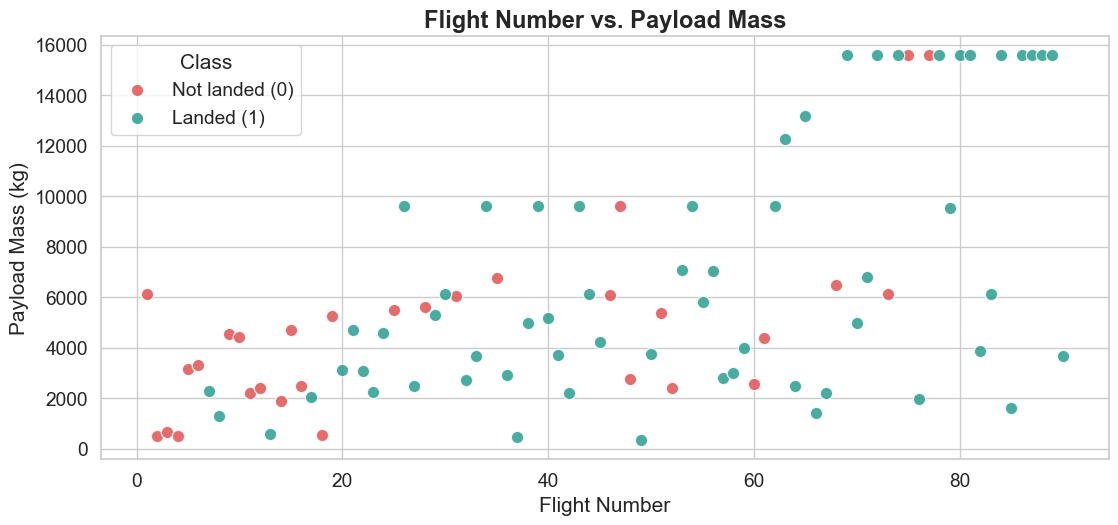

In [2]:
fig, ax = plt.subplots(figsize=(13, 5.5))
for c in [0, 1]:
    part = df[df["Class"] == c]
    ax.scatter(part["FlightNumber"], part["PayloadMass"], s=80, color=COLORS[c], alpha=0.85,
               label=["Not landed (0)", "Landed (1)"][c], edgecolor="white")
ax.set_xlabel("Flight Number"); ax.set_ylabel("Payload Mass (kg)")
ax.set_title("Flight Number vs. Payload Mass", fontsize=17, weight="bold"); ax.legend(title="Class")
save(fig, "eda_01_flight_vs_payload.png")

In [3]:
# numbers behind the insight: success rate of the first 30 flights vs. the last 30 flights
first, last = df.head(30)["Class"].mean(), df.tail(30)["Class"].mean()
print(f"flights 1-30: {first:.0%} | flights 61-90: {last:.0%}")
heavy = df[df["PayloadMass"] > 10000]
print(f"payload > 10,000 kg: {len(heavy)} launches, success rate {heavy['Class'].mean():.0%}")

flights 1-30: 43% | flights 61-90: 83%
payload > 10,000 kg: 15 launches, success rate 87%


**Insight:** As the flight number grows, landings succeed more often (43% for flights 1–30 vs. 83% for flights 61–90), and heavy payloads (> 10,000 kg) still landed in 87% of cases (13 of 15).

## 2. Flight Number vs. Launch Site

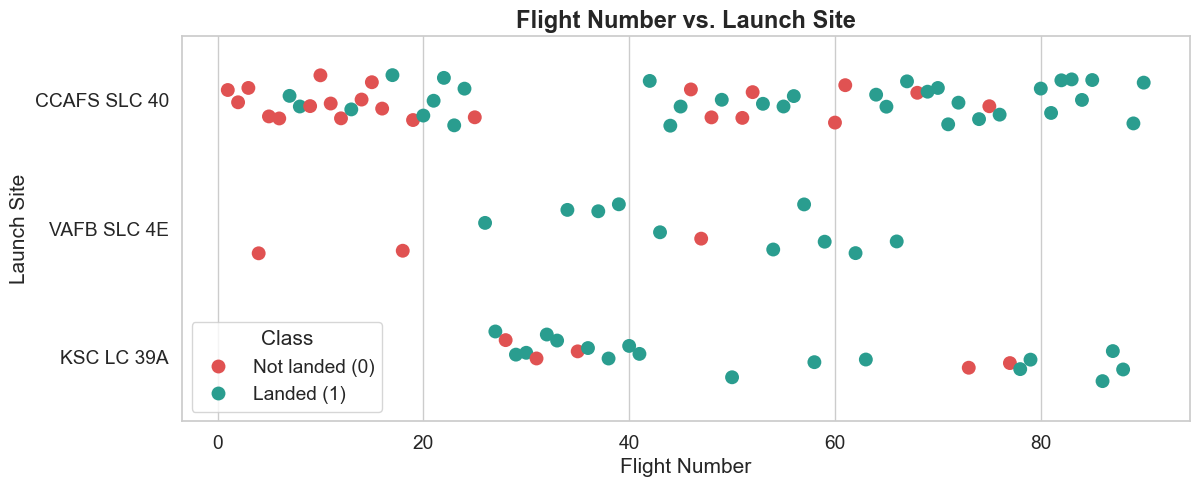

In [4]:
fig, ax = plt.subplots(figsize=(13, 5))
sns.stripplot(data=df, x="FlightNumber", y="LaunchSite", hue="Class", palette=COLORS, size=10, jitter=0.2, ax=ax)
ax.set_xlabel("Flight Number"); ax.set_ylabel("Launch Site")
ax.set_title("Flight Number vs. Launch Site", fontsize=17, weight="bold")
h, _ = ax.get_legend_handles_labels(); ax.legend(h, ["Not landed (0)", "Landed (1)"], title="Class")
save(fig, "eda_02_flight_vs_site.png")

In [5]:
site_stats = df.groupby("LaunchSite")["Class"].agg(launches="count", success_rate="mean")
site_stats["success_rate"] = (site_stats["success_rate"] * 100).round(1)
print(site_stats)
print()
print("CCAFS SLC 40 – first 20 launches there:", round(df[df.LaunchSite == "CCAFS SLC 40"].head(20)["Class"].mean() * 100, 1), "%")
print("CCAFS SLC 40 – later launches:", round(df[df.LaunchSite == "CCAFS SLC 40"].iloc[20:]["Class"].mean() * 100, 1), "%")

              launches  success_rate
LaunchSite                          
CCAFS SLC 40        55          60.0
KSC LC 39A          22          77.3
VAFB SLC 4E         13          76.9

CCAFS SLC 40 – first 20 launches there: 35.0 %
CCAFS SLC 40 – later launches: 74.3 %


**Insight:** CCAFS SLC 40 has the most launches (55) and the lowest rate (60%), because most early failed flights were there (35% in its first 20 launches vs. 74% later); KSC LC 39A (77%) and VAFB SLC 4E (77%) did better.

## 3. Payload Mass vs. Launch Site

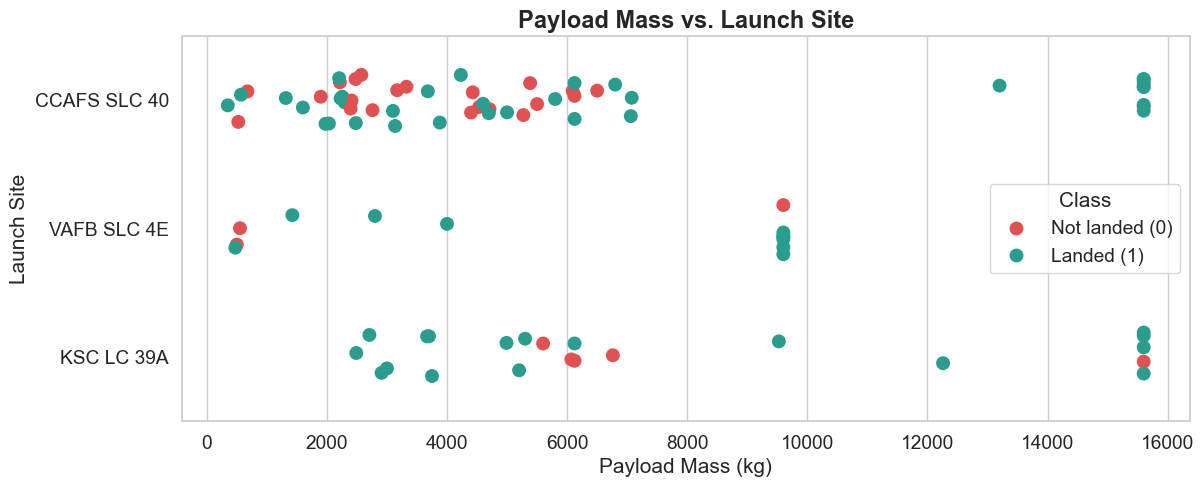

In [6]:
fig, ax = plt.subplots(figsize=(13, 5))
sns.stripplot(data=df, x="PayloadMass", y="LaunchSite", hue="Class", palette=COLORS, size=10, jitter=0.2, ax=ax)
ax.set_xlabel("Payload Mass (kg)"); ax.set_ylabel("Launch Site")
ax.set_title("Payload Mass vs. Launch Site", fontsize=17, weight="bold")
h, _ = ax.get_legend_handles_labels(); ax.legend(h, ["Not landed (0)", "Landed (1)"], title="Class")
save(fig, "eda_03_payload_vs_site.png")

In [7]:
print("max payload at VAFB SLC 4E:", df[df.LaunchSite == "VAFB SLC 4E"]["PayloadMass"].max(), "kg")
print("launches with payload > 10,000 kg by site:")
print(df[df.PayloadMass > 10000].groupby("LaunchSite")["Class"].agg(["count", "mean"]))

max payload at VAFB SLC 4E: 9600.0 kg
launches with payload > 10,000 kg by site:
              count      mean
LaunchSite                   
CCAFS SLC 40      9  0.888889
KSC LC 39A        6  0.833333


**Insight:** VAFB SLC 4E never launched a payload heavier than 9,600 kg, and every payload above 10,000 kg flew from CCAFS SLC 40 or KSC LC 39A with a high success rate (89% and 83%).

## 4. Success Rate by Orbit Type

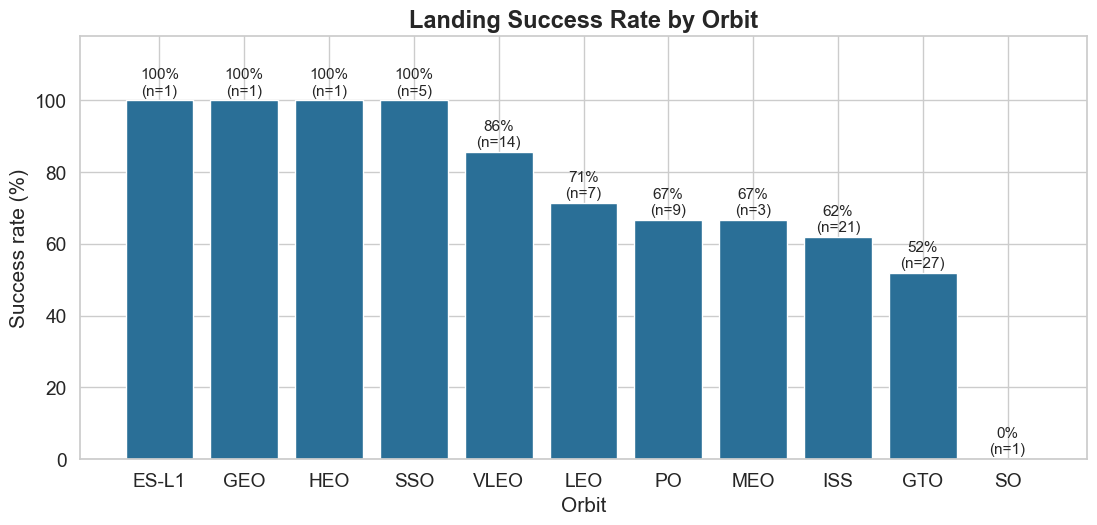

,mean,count
Orbit,,
ES-L1,100.0,1
GEO,100.0,1
HEO,100.0,1
SSO,100.0,5
VLEO,85.7,14
LEO,71.4,7
PO,66.7,9
MEO,66.7,3
ISS,61.9,21


In [8]:
orbit_rate = df.groupby("Orbit")["Class"].agg(["mean", "count"]).sort_values("mean", ascending=False)
fig, ax = plt.subplots(figsize=(13, 5.5))
bars = ax.bar(orbit_rate.index, orbit_rate["mean"] * 100, color="#2a6f97")
for b, (rate, n) in zip(bars, orbit_rate.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, f"{rate:.0%}\n(n={int(n)})", ha="center", fontsize=11)
ax.set_ylim(0, 118); ax.set_ylabel("Success rate (%)"); ax.set_xlabel("Orbit")
ax.set_title("Landing Success Rate by Orbit", fontsize=17, weight="bold")
save(fig, "eda_04_success_by_orbit.png")
(orbit_rate.assign(mean=lambda t: (t["mean"] * 100).round(1)))

**Insight:** SSO (5/5), ES-L1, GEO and HEO reached 100% but have very few launches; among the common orbits VLEO is best (86%, n=14) and GTO is worst (52%, n=27).

## 5. Flight Number vs. Orbit

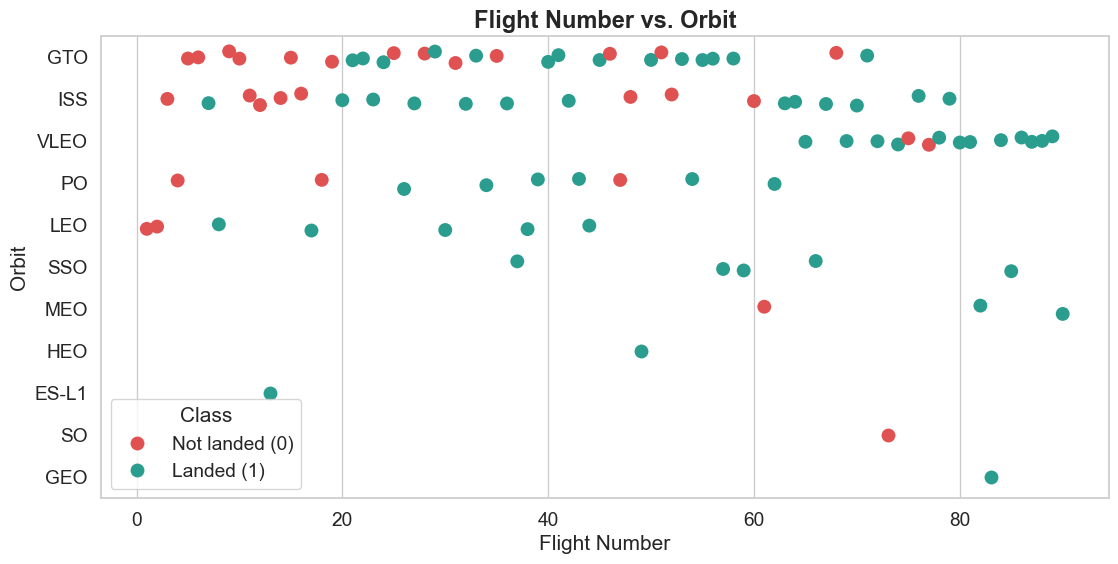

In [9]:
order = df["Orbit"].value_counts().index
fig, ax = plt.subplots(figsize=(13, 6))
sns.stripplot(data=df, x="FlightNumber", y="Orbit", hue="Class", order=order, palette=COLORS, size=10, jitter=0.15, ax=ax)
ax.set_xlabel("Flight Number"); ax.set_ylabel("Orbit")
ax.set_title("Flight Number vs. Orbit", fontsize=17, weight="bold")
h, _ = ax.get_legend_handles_labels(); ax.legend(h, ["Not landed (0)", "Landed (1)"], title="Class")
save(fig, "eda_05_flight_vs_orbit.png")

In [10]:
for o in ["LEO", "VLEO", "GTO"]:
    part = df[df.Orbit == o]
    print(f"{o}: flights {part.FlightNumber.min()}-{part.FlightNumber.max()}, success {part.Class.mean():.0%}")
leo = df[df.Orbit == "LEO"]
print("LEO first 3 flights Class:", leo.head(3)["Class"].tolist(), "| later:", leo.iloc[3:]["Class"].tolist())

LEO: flights 1-44, success 71%
VLEO: flights 65-89, success 86%
GTO: flights 5-71, success 52%
LEO first 3 flights Class: [0, 0, 1] | later: [1, 1, 1, 1]


**Insight:** In LEO the first two flights failed and all later ones landed, while GTO shows no clear improvement with flight number (52% overall); VLEO launches all came late (flights 65–89) and succeeded 86% of the time.

## 6. Payload Mass vs. Orbit

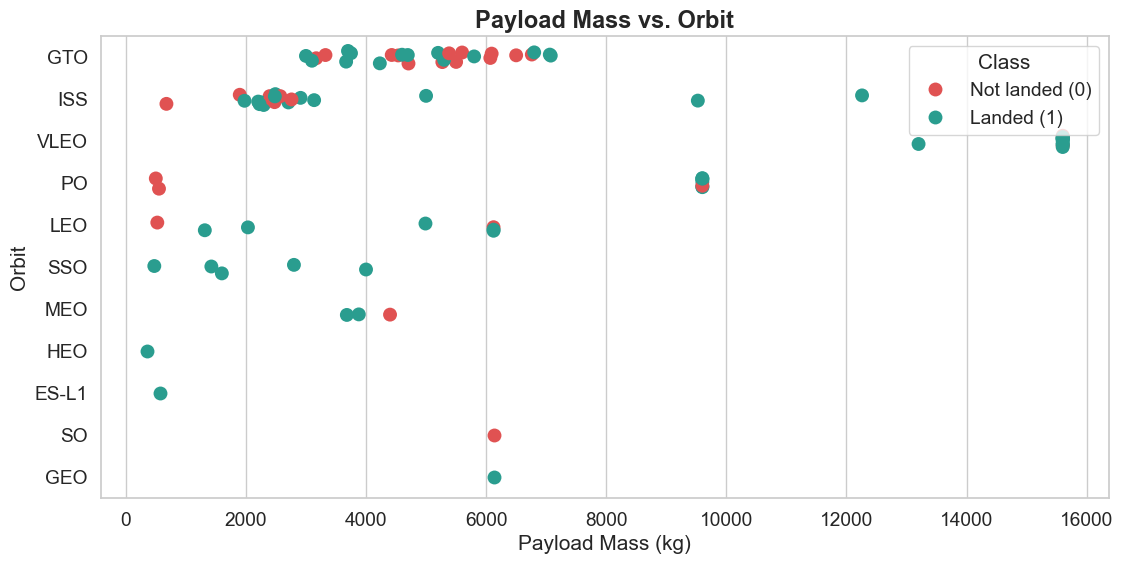

In [11]:
fig, ax = plt.subplots(figsize=(13, 6))
sns.stripplot(data=df, x="PayloadMass", y="Orbit", hue="Class", order=order, palette=COLORS, size=10, jitter=0.15, ax=ax)
ax.set_xlabel("Payload Mass (kg)"); ax.set_ylabel("Orbit")
ax.set_title("Payload Mass vs. Orbit", fontsize=17, weight="bold")
h, _ = ax.get_legend_handles_labels(); ax.legend(h, ["Not landed (0)", "Landed (1)"], title="Class")
save(fig, "eda_06_payload_vs_orbit.png")

In [12]:
for o in ["PO", "ISS", "GTO", "VLEO"]:
    part = df[df.Orbit == o]
    print(f"{o}: payload {part.PayloadMass.min():.0f}-{part.PayloadMass.max():.0f} kg, success {part.Class.mean():.0%}")
gto = df[df.Orbit == "GTO"]
print("GTO payload <= 5000 kg:", round(gto[gto.PayloadMass <= 5000].Class.mean() * 100, 1), "% | > 5000 kg:",
      round(gto[gto.PayloadMass > 5000].Class.mean() * 100, 1), "%")

PO: payload 500-9600 kg, success 67%
ISS: payload 677-12259 kg, success 62%
GTO: payload 3000-7076 kg, success 52%
VLEO: payload 13200-15600 kg, success 86%
GTO payload <= 5000 kg: 61.5 % | > 5000 kg: 42.9 %


**Insight:** Heavy payloads do well in VLEO (13,200–15,600 kg, 86%), but in GTO heavier payloads land less often (62% for ≤ 5,000 kg vs. 43% for > 5,000 kg).

## 7. Yearly Success Trend

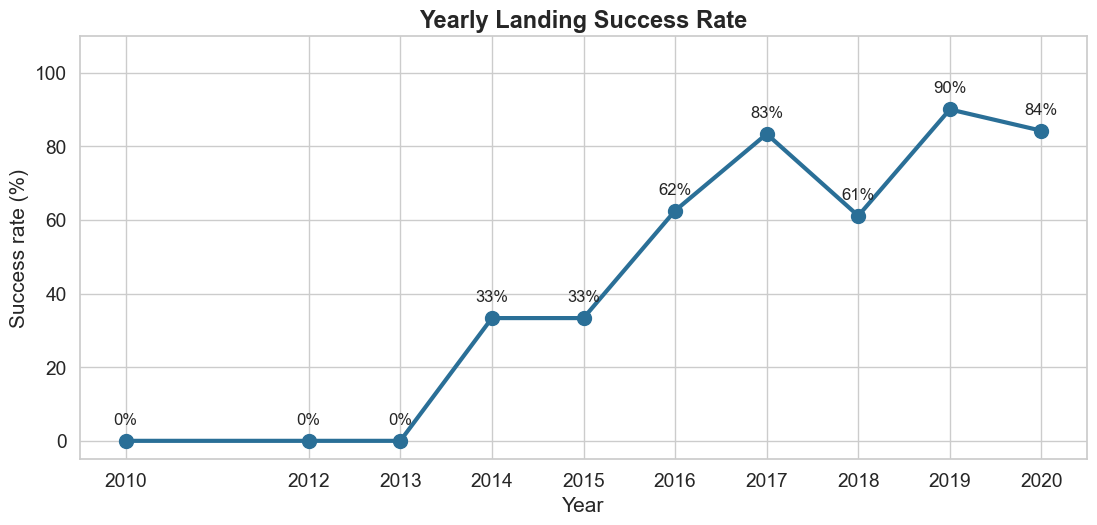

,mean,count
Year,,
2010,0.0,1
2012,0.0,1
2013,0.0,3
2014,33.3,6
2015,33.3,6
2016,62.5,8
2017,83.3,18
2018,61.1,18
2019,90.0,10


In [13]:
df["Year"] = pd.to_datetime(df["Date"]).dt.year
yearly = df.groupby("Year")["Class"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(yearly.index, yearly["mean"] * 100, marker="o", markersize=10, linewidth=3, color="#2a6f97")
for y, (rate, n) in yearly.iterrows():
    ax.annotate(f"{rate:.0%}", (y, rate * 100), textcoords="offset points", xytext=(0, 12), ha="center", fontsize=12)
ax.set_ylim(-5, 110); ax.set_xticks(yearly.index); ax.set_ylabel("Success rate (%)"); ax.set_xlabel("Year")
ax.set_title("Yearly Landing Success Rate", fontsize=17, weight="bold")
save(fig, "eda_07_yearly_trend.png")
yearly.assign(mean=lambda t: (t["mean"] * 100).round(1))

**Insight:** The success rate rose from 0% in 2010–2013 to 90% in 2019 (84% in 2020), with a dip in 2018 (61%), showing a clear learning curve.